<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2011/MRayhanZamzami_JS11_P4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 4 - Klasifikasi Citra Wajah dengan SVM dan PCA

Dataset: Labeled Faces in the Wild (LFW) dengan reduksi dimensi PCA dan tuning GridSearchCV.

## Langkah 0 - Unduh Dataset Citra Wajah

In [1]:
from sklearn.datasets import fetch_lfw_people

# Download dataset wajah publik figur
faces = fetch_lfw_people(min_faces_per_person=60)
print('Nama-nama target:')
print(faces.target_names)
print('Jumlah kelas target:', len(faces.target_names))
print('Dimensi data citra:', faces.images.shape)

Nama-nama target:
['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah kelas target: 8
Dimensi data citra: (1348, 62, 47)


## Langkah 1 - Inspeksi Citra Wajah

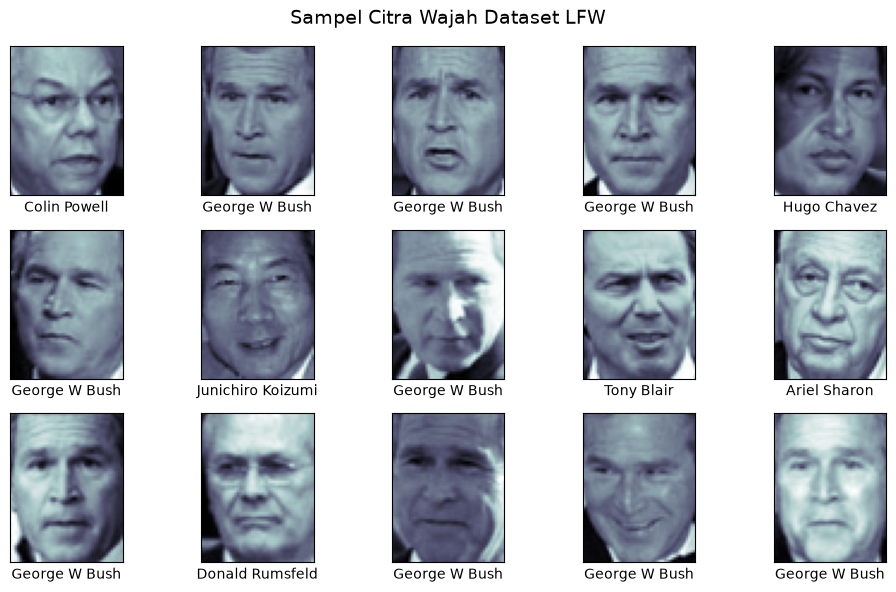

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(10, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.suptitle('Sampel Citra Wajah Dataset LFW', fontsize=14)
plt.tight_layout()
plt.show()

## Langkah 2 - Pipeline Ekstraksi Fitur (PCA) dan SVM

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

# 150 komponen utama mengekstrak fitur esensial wajah
pca = PCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data Training dan Testing

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    faces.data, faces.target, random_state=42, test_size=0.25
)
print('Data latih:', X_train.shape)
print('Data uji  :', X_test.shape)

Data latih: (1011, 2914)
Data uji  : (337, 2914)


## Langkah 4 - Hyperparameter Tuning dengan GridSearchCV

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

grid = GridSearchCV(model, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
final_model = grid.best_estimator_

Parameter terbaik: {'svc__C': 1, 'svc__gamma': 0.005}


## Langkah 5 - Prediksi dan Visualisasi Hasil Data Uji

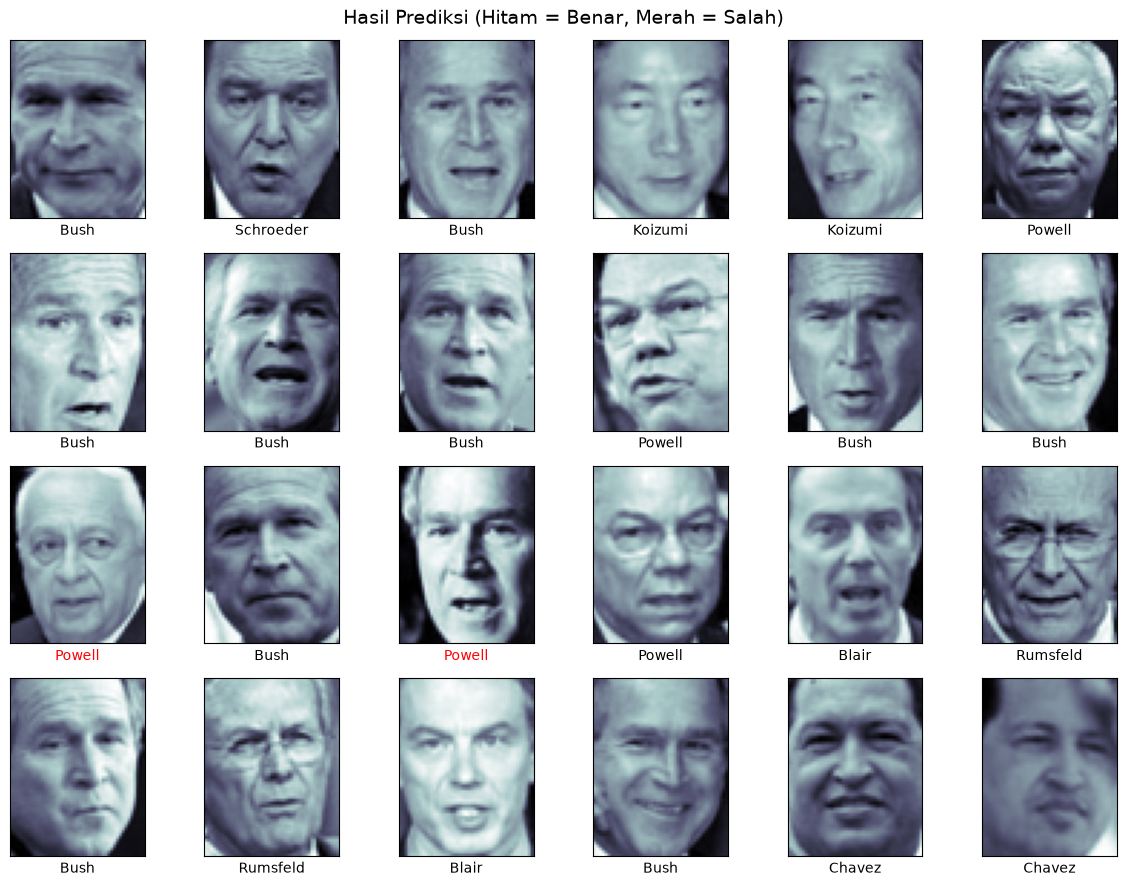

In [6]:
y_pred = final_model.predict(X_test)

fig, ax = plt.subplots(4, 6, figsize=(12, 9))
for i, axi in enumerate(ax.flat):
    axi.imshow(X_test[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    is_correct = (y_pred[i] == y_test[i])
    color = 'black' if is_correct else 'red'
    axi.set_xlabel(faces.target_names[y_pred[i]].split()[-1], color=color)

plt.suptitle('Hasil Prediksi (Hitam = Benar, Merah = Salah)', fontsize=14)
plt.tight_layout()
plt.show()

## Langkah 6 - Evaluasi Performa Model

Akurasi Pengenalan Wajah: 0.8753709198813057

Laporan Klasifikasi:
                   precision    recall  f1-score   support

     Ariel Sharon       0.92      0.80      0.86        15
     Colin Powell       0.74      0.94      0.83        68
  Donald Rumsfeld       0.83      0.81      0.82        31
    George W Bush       0.96      0.87      0.92       126
Gerhard Schroeder       0.83      0.83      0.83        23
      Hugo Chavez       1.00      0.75      0.86        20
Junichiro Koizumi       1.00      0.92      0.96        12
       Tony Blair       0.87      0.93      0.90        42

         accuracy                           0.88       337
        macro avg       0.89      0.86      0.87       337
     weighted avg       0.89      0.88      0.88       337



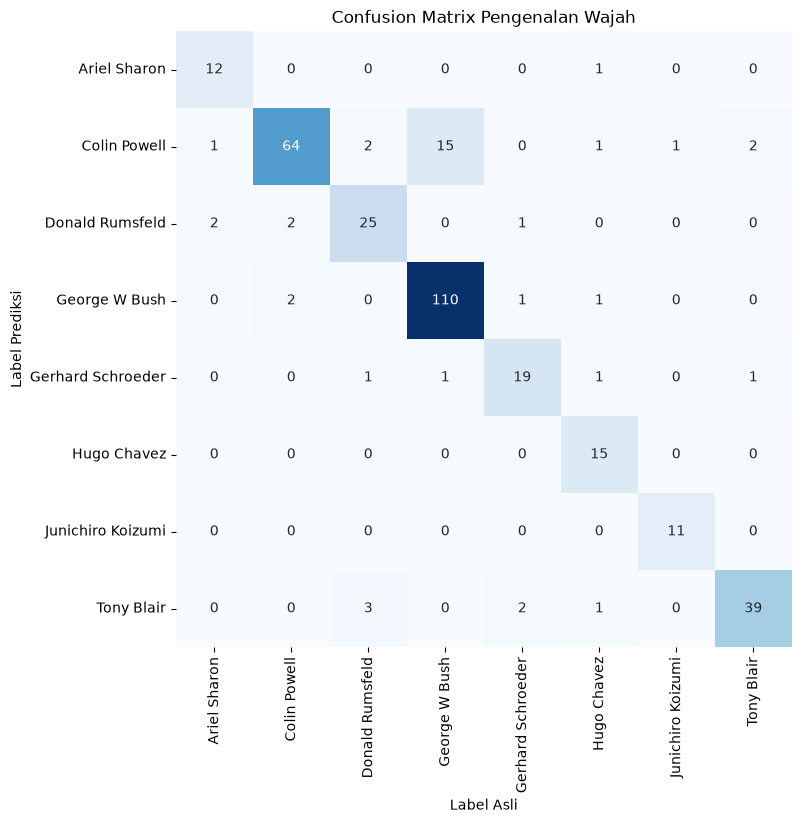

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

print('Akurasi Pengenalan Wajah:', accuracy_score(y_test, y_pred))
print('\nLaporan Klasifikasi:')
print(classification_report(y_test, y_pred, target_names=faces.target_names))

plt.figure(figsize=(10, 8))
mat = confusion_matrix(y_test, y_pred)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names, cmap='Blues')
plt.xlabel('Label Asli')
plt.ylabel('Label Prediksi')
plt.title('Confusion Matrix Pengenalan Wajah')
plt.show()